# 20. Alternating Forms and Determinants
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Signed area and volume. Left: the alternating form $\alpha(u,v)=u_1v_2-u_2v_1$ is the area of the parallelogram spanned by $u,v$ (blue, positive) and changes sign when the order is reversed or the orientation is flipped (red, negative). Right: the scalar triple product $u\cdot(v\times w)$ as the signed volume of a parallelepiped.

[]

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


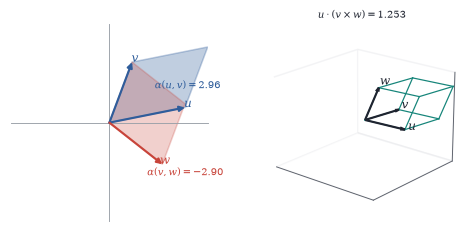

In [2]:
from itertools import product
fig = plt.figure(figsize=(W, 2.0))
ax = fig.add_subplot(121); plane(ax, 2.6, grid=False)
u, v = np.array([2.0, 0.4]), np.array([0.6, 1.6]); w2 = np.array([1.4, -1.1])
ax.fill(*np.c_[[0, 0], u, u + v, v], color=BLUE, alpha=0.3); arrow(ax, u, color=BLUE, label="$u$"); arrow(ax, v, color=BLUE, label="$v$")
ax.fill(*np.c_[[0, 0], v, v + w2, w2], color=RED, alpha=0.25); arrow(ax, w2, color=RED, label="$w$")
ax.text(1.2, 0.9, f"$\\alpha(u,v)={u[0] * v[1] - u[1] * v[0]:.2f}$", fontsize=6.5, color=BLUE)
ax.text(1.0, -1.4, f"$\\alpha(v,w)={v[0] * w2[1] - v[1] * w2[0]:.2f}$", fontsize=6.5, color=RED)
ax3 = ax3d(fig, 122, elev=20, azim=-50, lim=1.6)
P = np.array([[1.2, 0.1, 0.0], [0.3, 1.0, 0.1], [0.2, 0.3, 1.1]])
corners = np.array([a * P[0] + b * P[1] + c * P[2] for a, b, c in product([0, 1], repeat=3)])
for i in range(8):
    for j in range(i + 1, 8):
        if bin(i ^ j).count("1") == 1: ax3.plot(*np.c_[corners[i], corners[j]], color=TEAL, lw=0.8)
for k, lab in enumerate(["$u$", "$v$", "$w$"]): arrow3d(ax3, P[k], color=INK, label=lab)
ax3.set_title(f"$u\\cdot(v\\times w)={np.dot(P[0], np.cross(P[1], P[2])):.3f}$", fontsize=6.5)
ax3.set_xticks([]); ax3.set_yticks([]); ax3.set_zticks([])

In [3]:
import math, time
rng = np.random.default_rng(0); A = rng.normal(size=(6, 6))
from itertools import permutations
def sign(p):
    inv = sum(1 for i in range(len(p)) for j in range(i + 1, len(p)) if p[i] > p[j]); return -1 if inv % 2 else 1
leib = sum(sign(p) * np.prod([A[p[k], k] for k in range(6)]) for p in permutations(range(6)))
from scipy.linalg import lu
P, L, U = lu(A); viaLU = np.linalg.det(P) * np.prod(np.diag(U))
print(f"Leibniz (720 terms): {leib:.10f}   LU: {viaLU:.10f}   numpy: {np.linalg.det(A):.10f}")
print("terms in Leibniz formula for n = 10, 20, 50:", [f"{math.factorial(n):.2e}" for n in (10, 20, 50)])

Leibniz (720 terms): -2.3405106403   LU: -2.3405106403   numpy: -2.3405106403
terms in Leibniz formula for n = 10, 20, 50: ['3.63e+06', '2.43e+18', '3.04e+64']


$\det A$ as the area scale factor. The unit grid (light) and its image under $A=\begin{bmatrix}1.5&0.6\\0.4&1.2\end{bmatrix}$ (blue): every unit cell becomes a parallelogram of area $\det A=1.56$, and the shaded disc's area is multiplied by the same factor. Right: a map with negative determinant reverses orientation; the letter-shaped flag is mirrored.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


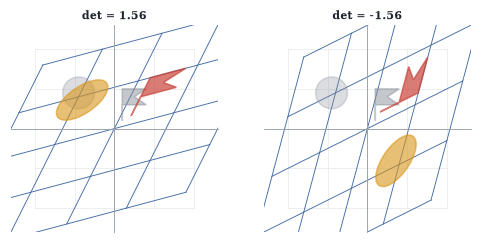

In [4]:
A = np.array([[1.5, 0.6], [0.4, 1.2]]); Bm = np.array([[0.4, 1.2], [1.5, 0.6]])
t = np.linspace(0, 2 * np.pi, 200); disc = np.vstack([0.4 * np.cos(t) - 0.9, 0.4 * np.sin(t) + 0.9])
flag = np.array([[0.2, 0.2, 0.8, 0.5, 0.8, 0.2], [0.2, 1.0, 1.0, 0.8, 0.6, 0.6]])
fig, axs = plt.subplots(1, 2, figsize=(W, 2.1))
for ax, M, ttl in [(axs[0], A, f"det = {np.linalg.det(A):.2f}"), (axs[1], Bm, f"det = {np.linalg.det(Bm):.2f}")]:
    plane(ax, 2.6, grid=False); grid_image(ax, M, lim=2, n=5)
    ax.fill(*disc, color=GRAY, alpha=0.3); ax.fill(*(M @ disc), color=GOLD, alpha=0.6)
    ax.fill(*flag, color=GRAY, alpha=0.5); ax.fill(*(M @ flag), color=RED, alpha=0.7); ax.set_title(ttl, fontsize=7)

In [5]:
rng = np.random.default_rng(1); n = 3
S = rng.normal(size=(n, n)); A = S @ S.T + np.eye(n)
exact = (2 * np.pi) ** (n / 2) / np.sqrt(np.linalg.det(A))
N = 400000; box = 6.0; X = rng.uniform(-box, box, size=(N, n))
mc = (2 * box) ** n * np.mean(np.exp(-0.5 * np.einsum("ij,jk,ik->i", X, A, X)))
print(f"(2 pi)^(n/2) det(A)^(-1/2) = {exact:.4f}    Monte Carlo estimate = {mc:.4f}")

(2 pi)^(n/2) det(A)^(-1/2) = 5.4645    Monte Carlo estimate = 5.3878


In [6]:
rng = np.random.default_rng(2); M = rng.normal(size=(4, 4)); A = M - M.T
pf = A[0, 1] * A[2, 3] - A[0, 2] * A[1, 3] + A[0, 3] * A[1, 2]
print(f"Pf(A)^2 = {pf ** 2:.10f}   det(A) = {np.linalg.det(A):.10f}")
B5 = rng.normal(size=(5, 5)); print("det of a 5x5 skew matrix:", round(np.linalg.det(B5 - B5.T), 12))
from itertools import combinations
Ar, Br = rng.normal(size=(2, 4)), rng.normal(size=(4, 2))
cb = sum(np.linalg.det(Ar[:, list(S)]) * np.linalg.det(Br[list(S), :]) for S in combinations(range(4), 2))
print(f"Cauchy-Binet: det(AB) = {np.linalg.det(Ar @ Br):.10f}   sum over 2x2 minors = {cb:.10f}")

Pf(A)^2 = 5.6765308636   det(A) = 5.6765308636
det of a 5x5 skew matrix: 0.0
Cauchy-Binet: det(AB) = -4.5453782973   sum over 2x2 minors = -4.5453782973


Independent random points (left) versus a determinantal point process on a $30\times30$ grid with a Gaussian similarity kernel (right), both with about the same number of points. The independent points clump and leave gaps; the determinantal sample spreads out evenly, because nearby points have nearly parallel feature vectors and therefore small Gram determinant.

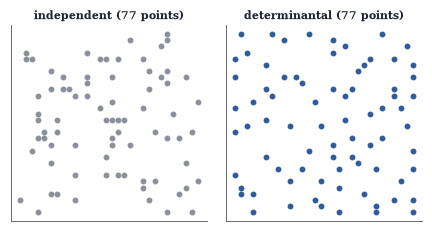

In [7]:
rng = np.random.default_rng(3); g = np.linspace(0, 1, 30); G = np.array([(x, y) for x in g for y in g])
D2 = ((G[:, None, :] - G[None, :, :]) ** 2).sum(-1); Lk = 20 * np.exp(-D2 / (2 * 0.15 ** 2))
lam, V = np.linalg.eigh(Lk); keep = rng.random(len(lam)) < lam / (1 + lam); Vs = V[:, keep]; chosen = []
while Vs.shape[1] > 0:                                      # spectral sampling algorithm for DPPs
    p = np.sum(Vs ** 2, axis=1) / Vs.shape[1]; i = rng.choice(len(p), p=p / p.sum()); chosen.append(i)
    j = np.argmax(np.abs(Vs[i])); Vj = Vs[:, j]; Vs = np.delete(Vs, j, axis=1)
    Vs = Vs - np.outer(Vj, Vs[i] / Vj[i])
    if Vs.shape[1] > 0: Vs, _ = np.linalg.qr(Vs)
ind = rng.choice(len(G), size=len(chosen), replace=False)
fig, axs = plt.subplots(1, 2, figsize=(W * 0.85, 2.0))
for ax, idx, col, ttl in [(axs[0], ind, GRAY, "independent"), (axs[1], np.array(chosen), BLUE, "determinantal")]:
    ax.scatter(*G[idx].T, s=8, color=col); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{ttl} ({len(idx)} points)", fontsize=7)

Hadamard's bound. For $2000$ random $n\times n$ matrices with entries $\pm1$, the ratio $\lvert\det A\rvert/n^{n/2}$ of the determinant to Hadamard's bound (the product of the column lengths). The bound is attained only by Hadamard matrices with orthogonal columns, such as the Sylvester construction for $n=4,8,16$ (red markers at $1$); typical random sign matrices fall exponentially short.

Text(0, 0.5, '$|\\det A|/n^{n/2}$')

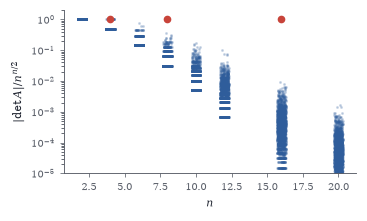

In [8]:
rng = np.random.default_rng(4); ns = [2, 4, 6, 8, 10, 12, 16, 20]
fig, ax = plt.subplots(figsize=(W * 0.7, 1.9))
for n in ns:
    r = np.abs(np.linalg.det(rng.choice([-1.0, 1.0], size=(2000, n, n)))) / n ** (n / 2)
    ax.scatter(np.full(r.size, n) + rng.uniform(-0.3, 0.3, r.size), np.maximum(r, 1e-6), s=1, color=BLUE, alpha=0.2)
H = np.array([[1.0]])
for k in range(4):
    H = np.block([[H, H], [H, -H]])
    if H.shape[0] in (4, 8, 16): ax.plot(H.shape[0], abs(np.linalg.det(H)) / H.shape[0] ** (H.shape[0] / 2), "o", color=RED, ms=4)
ax.set_yscale("log"); ax.set_ylim(1e-5, 2); ax.set_xlabel("$n$"); ax.set_ylabel(r"$|\det A|/n^{n/2}$")

In [9]:
for n in (5, 10, 15, 20):
    eq = np.linspace(0, 1, n); ch = 0.5 - 0.5 * np.cos((2 * np.arange(n) + 1) * np.pi / (2 * n))
    print(f"n = {n:2d}: cond(equispaced) = {np.linalg.cond(np.vander(eq, increasing=True)):.2e}   cond(Chebyshev) = {np.linalg.cond(np.vander(ch, increasing=True)):.2e}")

n =  5: cond(equispaced) = 6.86e+02   cond(Chebyshev) = 6.27e+02
n = 10: cond(equispaced) = 1.52e+07   cond(Chebyshev) = 3.98e+06
n = 15: cond(equispaced) = 4.03e+11   cond(Chebyshev) = 2.62e+10
n = 20: cond(equispaced) = 1.17e+16   cond(Chebyshev) = 1.74e+14
